In [2]:
%pip install duckdb pandas scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 11.2 MB/s  0:00:01 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [1]:
import duckdb
con = duckdb.connect('../data/nba.duckdb')
con.sql("INSTALL sqlite; LOAD sqlite; ATTACH '../data/NBA.sqlite' AS nba (TYPE sqlite, READ_ONLY);")

BinderException: Binder Error: Failed to attach database: database with name "nba" already exists

In [2]:
con.sql("SELECT table_name FROM duckdb_tables() WHERE database_name = 'nba'").df()

,table_name
0,game
1,game_summary
2,other_stats
3,officials
4,inactive_players
5,game_info
6,line_score
7,play_by_play
8,player
9,team


In [3]:
con.sql("DESCRIBE nba.play_by_play").df()

,column_name,column_type,null,key,default,extra
0,game_id,VARCHAR,YES,None,None,None
1,eventnum,BIGINT,YES,None,None,None
2,eventmsgtype,BIGINT,YES,None,None,None
3,eventmsgactiontype,BIGINT,YES,None,None,None
4,period,BIGINT,YES,None,None,None
5,wctimestring,VARCHAR,YES,None,None,None
6,pctimestring,VARCHAR,YES,None,None,None
7,homedescription,VARCHAR,YES,None,None,None
8,neutraldescription,VARCHAR,YES,None,None,None
9,visitordescription,VARCHAR,YES,None,None,None


In [4]:
con.sql("""
    SELECT g.season_id, g.game_date, p.eventmsgtype, p.eventmsgactiontype,
           p.homedescription, p.visitordescription, p.player1_name
    FROM nba.play_by_play p
    JOIN nba.game g ON p.game_id = g.game_id
    WHERE p.eventmsgtype IN (1, 2)
    ORDER BY g.game_date DESC
    LIMIT 20
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,season_id,game_date,eventmsgtype,eventmsgactiontype,homedescription,visitordescription,player1_name
0,42022,2023-06-09,2,1,MISS Vincent 28' 3PT Jump Shot,None,Gabe Vincent
1,42022,2023-06-09,2,101,None,MISS Jokic 7' Driving Floating Jump Shot,Nikola Jokic
2,42022,2023-06-09,2,75,None,MISS Jokic 5' Driving Finger Roll Layup,Nikola Jokic
3,42022,2023-06-09,2,47,MISS Adebayo 13' Turnaround Jump Shot,None,Bam Adebayo
4,42022,2023-06-09,1,1,Love 25' 3PT Jump Shot (3 PTS) (Butler 1 AST),None,Kevin Love
5,42022,2023-06-09,2,1,MISS Strus 24' 3PT Jump Shot,None,Max Strus
6,42022,2023-06-09,1,102,None,Murray 2' Driving Floating Bank Jump Shot (3 P...,Jamal Murray
7,42022,2023-06-09,2,1,MISS Vincent 24' 3PT Jump Shot,None,Gabe Vincent
8,42022,2023-06-09,2,1,MISS Butler 24' 3PT Jump Shot,None,Jimmy Butler
9,42022,2023-06-09,1,1,None,Caldwell-Pope 3PT Jump Shot (3 PTS) (Jokic 1 AST),Kentavious Caldwell-Pope


In [5]:
import duckdb
con = duckdb.connect('../data/nba.duckdb')
con.sql("INSTALL sqlite; LOAD sqlite; ATTACH '../data/NBA.sqlite' AS nba (TYPE sqlite, READ_ONLY);")

BinderException: Binder Error: Failed to attach database: database with name "nba" already exists

In [7]:
import duckdb
con = duckdb.connect('../data/project.duckdb')
con.sql("INSTALL sqlite; LOAD sqlite; ATTACH '../data/NBA.sqlite' AS nba (TYPE sqlite, READ_ONLY);")

SuccessBOOLEAN


In [8]:
con.sql(r"""
CREATE OR REPLACE TABLE shots AS
WITH raw AS (
    SELECT
        g.season_id,
        CAST(RIGHT(g.season_id, 4) AS INT)            AS season,
        p.game_id,
        g.game_date,
        p.player1_id                                   AS player_id,
        p.player1_name                                 AS player,
        p.player1_team_abbreviation                    AS team,
        p.period,
        p.pctimestring,
        p.eventmsgactiontype                           AS action_type,
        CASE WHEN p.player1_team_id = g.team_id_home
             THEN p.homedescription
             ELSE p.visitordescription END             AS descr,
        CASE WHEN p.eventmsgtype = 1 THEN 1 ELSE 0 END AS made
    FROM nba.play_by_play p
    JOIN nba.game g ON p.game_id = g.game_id
    WHERE p.eventmsgtype IN (1, 2)
      AND g.season_id BETWEEN '22018' AND '22022'
)
SELECT *,
    TRY_CAST(regexp_extract(descr, '(\d+)''', 1) AS INT)        AS distance_ft,
    CASE WHEN descr LIKE '%3PT%' THEN 1 ELSE 0 END              AS is_three,
    CAST(split_part(pctimestring, ':', 1) AS INT) * 60
      + CAST(split_part(pctimestring, ':', 2) AS INT)           AS secs_left_in_period
FROM raw
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CountBIGINT
937759


In [9]:
con.sql("""
SELECT season,
       COUNT(*)                                   AS shots,
       ROUND(AVG(made), 3)                        AS fg_pct,
       ROUND(AVG(distance_ft IS NULL::INT), 3)    AS pct_missing_distance,
       ROUND(AVG(is_three), 3)                    AS three_rate
FROM shots
GROUP BY season
ORDER BY season
""").df()

,season,shots,fg_pct,pct_missing_distance,three_rate
0,2018,200166,0.461,0.535,0.179
1,2019,171137,0.460,0.536,0.193
2,2020,174877,0.466,0.549,0.196
3,2021,196159,0.461,0.552,0.198
4,2022,195420,0.475,0.550,0.193


In [10]:
con.sql(r"""
CREATE OR REPLACE TABLE shots AS
WITH raw AS (
    SELECT
        g.season_id,
        CAST(RIGHT(g.season_id, 4) AS INT)            AS season,
        p.game_id,
        g.game_date,
        p.player1_id                                   AS player_id,
        p.player1_name                                 AS player,
        p.player1_team_abbreviation                    AS team,
        p.period,
        p.pctimestring,
        p.eventmsgactiontype                           AS action_type,
        CASE WHEN p.homedescription IS NOT NULL
              AND p.homedescription NOT LIKE '% BLOCK (%'
             THEN p.homedescription
             ELSE p.visitordescription END             AS descr,
        CASE WHEN p.eventmsgtype = 1 THEN 1 ELSE 0 END AS made
    FROM nba.play_by_play p
    JOIN nba.game g ON p.game_id = g.game_id
    WHERE p.eventmsgtype IN (1, 2)
      AND g.season_id BETWEEN '22018' AND '22022'
)
SELECT *,
    TRY_CAST(regexp_extract(descr, '(\d+)''', 1) AS INT)        AS distance_ft,
    CASE WHEN descr LIKE '%3PT%' THEN 1 ELSE 0 END              AS is_three,
    CAST(split_part(pctimestring, ':', 1) AS INT) * 60
      + CAST(split_part(pctimestring, ':', 2) AS INT)           AS secs_left_in_period
FROM raw
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CountBIGINT
937759


In [11]:
con.sql("""
SELECT season,
       COUNT(*)                                   AS shots,
       ROUND(AVG(made), 3)                        AS fg_pct,
       ROUND(AVG(distance_ft IS NULL::INT), 3)    AS pct_missing_distance,
       ROUND(AVG(is_three), 3)                    AS three_rate
FROM shots
GROUP BY season
ORDER BY season
""").df()

,season,shots,fg_pct,pct_missing_distance,three_rate
0,2018,200166,0.461,0.071,0.359
1,2019,171137,0.460,0.071,0.384
2,2020,174877,0.466,0.102,0.392
3,2021,196159,0.461,0.104,0.400
4,2022,195420,0.475,0.102,0.387


In [12]:
con.sql("""
SELECT is_three, action_type,
       COUNT(*)                AS n_missing,
       ANY_VALUE(descr)        AS example
FROM shots
WHERE distance_ft IS NULL
GROUP BY is_three, action_type
ORDER BY n_missing DESC
LIMIT 15
""").df()

,is_three,action_type,n_missing,example
0,1,1,51591,MISS B. Lopez 3PT Jump Shot
1,0,97,10248,MISS Embiid Tip Layup Shot
2,0,72,2979,MISS Valanciunas Putback Layup
3,1,80,2061,MISS LeVert 3PT Step Back Jump Shot
4,0,6,1954,Butler Driving Layup (9 PTS)
5,0,107,1822,Martin Tip Dunk Shot (12 PTS)
6,1,2,1802,Siakam 3PT Running Jump Shot (12 PTS) (Lowry 2...
7,0,108,1475,Zubac Cutting Dunk Shot (6 PTS) (Leonard 3 AST)
8,0,50,1028,Leonard Running Dunk (25 PTS) (Shamet 1 AST)
9,1,79,928,Finney-Smith 3PT Pullup Jump Shot (4 PTS) (Cur...


In [13]:
con.sql("""
CREATE OR REPLACE TABLE shots_clean AS
WITH medians AS (
    SELECT action_type, is_three,
           MEDIAN(distance_ft) AS med_dist
    FROM shots
    WHERE distance_ft IS NOT NULL
    GROUP BY action_type, is_three
)
SELECT s.*,
       COALESCE(s.distance_ft, m.med_dist,
                CASE WHEN s.is_three = 1 THEN 25 ELSE 2 END) AS dist,
       (s.distance_ft IS NULL)::INT                         AS dist_imputed
FROM shots s
LEFT JOIN medians m
  ON s.action_type = m.action_type AND s.is_three = m.is_three
""")

con.sql("""
SELECT COUNT(*) AS shots,
       SUM(dist IS NULL::INT) AS still_missing,
       ROUND(AVG(dist_imputed), 3) AS pct_imputed
FROM shots_clean
""").df()

,shots,still_missing,pct_imputed
0,937759,0.0,0.09


In [14]:
con.sql("""
SELECT is_three, dist_imputed,
       COUNT(*) AS shots,
       ROUND(AVG(made), 3) AS fg_pct
FROM shots_clean
GROUP BY is_three, dist_imputed
ORDER BY is_three, dist_imputed
""").df()

,is_three,dist_imputed,shots,fg_pct
0,0,0,549908,0.521
1,0,1,27632,0.724
2,1,0,303279,0.353
3,1,1,56940,0.388


In [1]:
import duckdb
con = duckdb.connect('../data/project.duckdb')
con.sql("INSTALL sqlite; LOAD sqlite; ATTACH '../data/NBA.sqlite' AS nba (TYPE sqlite, READ_ONLY);")

SuccessBOOLEAN


In [2]:
con.sql("SELECT COUNT(*) FROM shots_clean").df()

,count_star()
0,937759


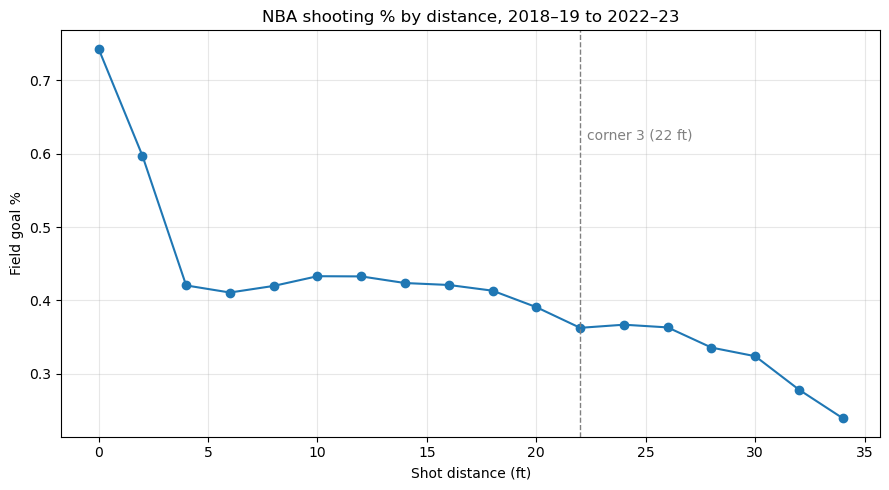

,dist_bucket,shots,fg_pct
0,0.0,113965,0.743193
1,2.0,156128,0.597529
2,4.0,59662,0.420502
3,6.0,44645,0.410819
4,8.0,35068,0.419841
5,10.0,32431,0.433073
6,12.0,30912,0.432809
7,14.0,27329,0.423762
8,16.0,27937,0.421126
9,18.0,25023,0.413340


In [3]:
import matplotlib.pyplot as plt

by_dist = con.sql("""
SELECT FLOOR(dist / 2) * 2 AS dist_bucket,
       COUNT(*)            AS shots,
       AVG(made)           AS fg_pct
FROM shots_clean
WHERE dist <= 35
GROUP BY dist_bucket
ORDER BY dist_bucket
""").df()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(by_dist['dist_bucket'], by_dist['fg_pct'], marker='o')
ax.axvline(22, linestyle='--', color='gray', linewidth=1)
ax.text(22.3, 0.62, 'corner 3 (22 ft)', color='gray')
ax.set_xlabel('Shot distance (ft)')
ax.set_ylabel('Field goal %')
ax.set_title('NBA shooting % by distance, 2018–19 to 2022–23')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fg_pct_by_distance.png', dpi=200)
plt.show()

by_dist

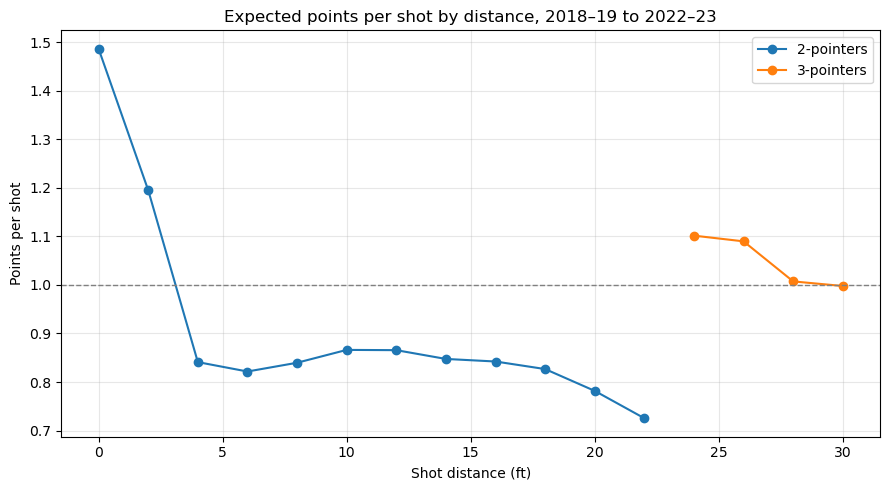

In [4]:
pps = con.sql("""
SELECT FLOOR(dist / 2) * 2                          AS dist_bucket,
       is_three,
       COUNT(*)                                     AS shots,
       AVG(made) * CASE WHEN is_three = 1 THEN 3 ELSE 2 END AS pts_per_shot
FROM shots_clean
WHERE dist <= 30
GROUP BY dist_bucket, is_three
HAVING COUNT(*) >= 500
ORDER BY dist_bucket
""").df()

fig, ax = plt.subplots(figsize=(9, 5))
for flag, label in [(0, '2-pointers'), (1, '3-pointers')]:
    d = pps[pps['is_three'] == flag]
    ax.plot(d['dist_bucket'], d['pts_per_shot'], marker='o', label=label)
ax.axhline(1.0, linestyle='--', color='gray', linewidth=1)
ax.set_xlabel('Shot distance (ft)')
ax.set_ylabel('Points per shot')
ax.set_title('Expected points per shot by distance, 2018–19 to 2022–23')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/points_per_shot_by_distance.png', dpi=200)
plt.show()